# 04 — Elo Testing

In this notebook I evaluate the Elo features added to the UFC fight prediction pipeline.

The goal is **not** to assume that Elo improves the model just because it makes sense conceptually. I want to test it against the current baseline under the same temporal split and the same model configuration.

The Elo system currently contains four independent ratings:

- **General Elo** — overall ability to win UFC fights.
- **Striking Elo** — relative striking performance, including KO/TKO information.
- **Grappling Offense Elo** — ability to impose takedowns, control and submission threats.
- **Grappling Defense Elo** — ability to defend takedowns and recover from grappling situations.

I also include:

- `is_debutant`
- Elo confidence features
- raw and inactivity-adjusted effective Elo
- a gradual inactivity decay after approximately 10 months

The main metric remains **Log Loss**, because the final objective of the project is to produce good probability estimates, not only correct winner labels.

## Experiments

I compare the following feature strategies:

1. **Baseline** — the original model without any Elo information.
2. **Baseline + General Elo** — tests whether opponent-adjusted overall strength is useful.
3. **Baseline + General + Striking Elo** — isolates the contribution of the striking rating.
4. **Baseline + General + Grappling Elo** — isolates the contribution of grappling offense/defense.
5. **Baseline + All Raw Elo** — uses the ratings before inactivity decay.
6. **Baseline + All Effective Elo** — uses the inactivity-adjusted ratings.
7. **Baseline + All Elo** — uses both raw and effective ratings.
8. **Elo-focused model** — keeps Elo, physical information, experience and matchup categories while removing most detailed performance statistics.
9. **All Elo without source statistics** — keeps the normal baseline structure but removes the main statistics used to construct the specialized Elo ratings.

The last two experiments are useful for checking whether Elo is **replacing** information or adding a genuinely different signal.

I use the validation set for model selection. The final test evaluation is disabled by default so I do not repeatedly optimize against the test set.

In [1]:
from __future__ import annotations

import json
import math
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)


## Project paths and experiment configuration

I keep the main settings in one place so I can rerun exactly the same comparison later.

The split is chronological. I do **not** shuffle fights because that would allow information from later UFC periods to influence the evaluation of earlier periods.

In [4]:
def find_project_root() -> Path:
    # I search upwards so this notebook works both from /notebooks and from the project root.
    starts = [Path.cwd(), Path.cwd().parent]

    for start in starts:
        for path in [start, *start.parents]:
            if (path / "src").exists() and (path / "data").exists():
                return path

    raise FileNotFoundError(
        "Could not locate the UFC_PREDICTOR project root. "
        "Run this notebook from inside the project."
    )


PROJECT_ROOT = find_project_root()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "ufcstats"
DATASET_PATH = PROCESSED_DIR / "fight_dataset.parquet"
REPORT_PATH = PROCESSED_DIR / "fight_dataset_report.json"

RESULTS_DIR = PROJECT_ROOT / "reports" / "elo_testing"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Temporal split.
TRAIN_FRACTION = 0.70
VALIDATION_FRACTION = 0.15
# The remaining 15% is kept as the final test set.

# I leave the final test disabled while I am still choosing the Elo strategy.
RUN_FINAL_TEST = False

# Random Forest is useful as a secondary check, but CatBoost is the main model.
RUN_RANDOM_FOREST = True

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATASET_PATH)
print("Results:", RESULTS_DIR)


Project root: c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR
Dataset: c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\data\processed\ufcstats\fight_dataset.parquet
Results: c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\reports\elo_testing


## Load the fight-level dataset

This notebook expects `fight_dataset.parquet` to have been regenerated **after** creating `fighter_elo_snapshots.parquet`.

If the Elo columns are not present, I stop here rather than silently running an experiment on the old dataset.

In [5]:
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"{DATASET_PATH} does not exist. "
        "Run the feature-building pipeline before this notebook."
    )

if not REPORT_PATH.exists():
    raise FileNotFoundError(
        f"{REPORT_PATH} does not exist. "
        "Rebuild the fight dataset so the feature manifest is available."
    )

df = pd.read_parquet(DATASET_PATH)

with REPORT_PATH.open("r", encoding="utf-8") as f:
    report = json.load(f)

df["event_date"] = pd.to_datetime(df["event_date"])

required_elo_markers = [
    "elo_general_raw_before",
    "elo_striking_raw_before",
    "elo_grappling_offense_raw_before",
    "elo_grappling_defense_raw_before",
]

missing_markers = [
    marker
    for marker in required_elo_markers
    if not any(marker in col for col in df.columns)
]

if missing_markers:
    raise ValueError(
        "The dataset does not appear to contain the new Elo features. "
        f"Missing markers: {missing_markers}"
    )

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print(f"Date range: {df['event_date'].min().date()} -> {df['event_date'].max().date()}")
print(f"Target mean: {df['target'].mean():.3f}")


Rows: 8,731
Columns: 170
Date range: 1994-03-11 -> 2026-09-12
Target mean: 0.500


In [6]:
# I inspect the Elo columns before training anything.
elo_columns = [
    col
    for col in df.columns
    if "elo_" in col or col.endswith("_is_debutant")
]

print(f"Elo-related columns: {len(elo_columns)}")
display(pd.DataFrame({"column": elo_columns}))


Elo-related columns: 44


,column
0,fighter_a_is_debutant
1,fighter_a_elo_confidence
2,fighter_a_elo_striking_confidence
3,fighter_a_elo_grappling_offense_confidence
4,fighter_a_elo_grappling_defense_confidence
5,fighter_a_elo_days_inactive_before
6,fighter_a_elo_decay_fraction_before
7,fighter_a_elo_general_raw_before
8,fighter_a_elo_general_effective_before
9,fighter_a_elo_striking_raw_before


## Basic Elo sanity checks

Before comparing models, I want to verify that the generated Elo data follows the rules I intended:

- debutants should not receive inactivity decay,
- confidence values should remain between 0 and 1,
- decay should remain between 0 and 1,
- the effective rating should move a raw rating **towards 1500**, never farther away.

These tests are deliberately simple. Their purpose is to catch feature-generation errors before they contaminate the model comparison.

In [8]:
debutant_cols = [
    col for col in df.columns
    if col.endswith("_is_debutant")
]

confidence_cols = [
    col for col in df.columns
    if (
        "elo_" in col
        and "confidence" in col
        and not col.startswith("diff_")
    )
]

decay_cols = [
    col for col in df.columns
    if (
        col.endswith("elo_decay_fraction_before")
        and not col.startswith("diff_")
    )
]

diff_decay_cols = [
    col for col in df.columns
    if (
        col.startswith("diff_")
        and col.endswith("elo_decay_fraction_before")
    )
]

raw_rating_cols = [
    col for col in df.columns
    if (
        "_elo_" in col
        and "_raw_before" in col
        and not col.startswith("diff_")
    )
]

assert debutant_cols, "No debutant columns found."
assert confidence_cols, "No Elo confidence columns found."
assert decay_cols, "No Elo decay columns found."
assert raw_rating_cols, "No raw Elo columns found."

# Individual confidence and decay values must be probabilities/fractions.
for col in confidence_cols + decay_cols:
    values = pd.to_numeric(df[col], errors="coerce").dropna()

    assert values.between(0, 1).all(), (
        f"{col} contains values outside [0, 1]."
    )

# A-B differences can naturally be negative.
for col in diff_decay_cols:
    values = pd.to_numeric(df[col], errors="coerce").dropna()

    assert values.between(-1, 1).all(), (
        f"{col} contains values outside [-1, 1]."
    )

## Inspect the inactivity decay

I want to see whether the decay behaves gradually rather than acting like a hard penalty.

This is not a model evaluation yet; it is only a feature sanity check.

,count,mean,median,max
inactivity_bin,,,,
"[0.0, 180.0)",8014,0.0,0.0,0.0
"[180.0, 304.0)",4434,0.0,0.0,0.0
"[304.0, 365.0)",789,0.01369,0.013105,0.032877
"[365.0, 548.0)",942,0.058335,0.05449,0.117566
"[548.0, 730.0)",264,0.127464,0.12784,0.181321
"[730.0, 1095.0)",177,0.190766,0.188634,0.272547
"[1095.0, inf)",132,0.304465,0.298619,0.40955


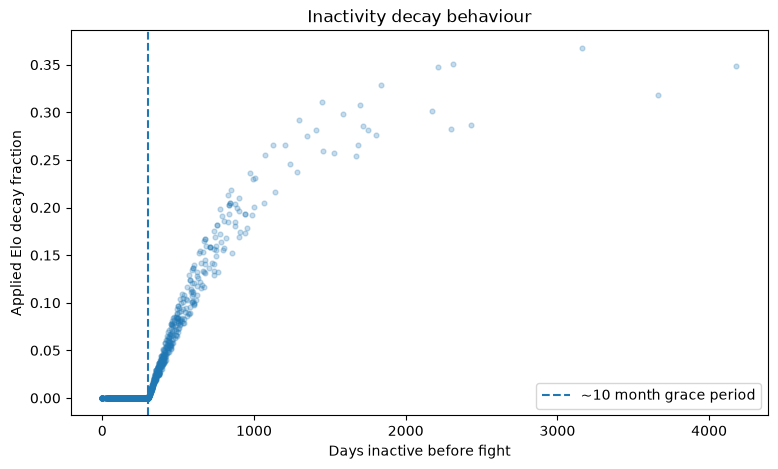

In [9]:
decay_view = pd.DataFrame({
    "days_inactive": pd.concat([
        pd.to_numeric(df.get("fighter_a_elo_days_inactive_before"), errors="coerce"),
        pd.to_numeric(df.get("fighter_b_elo_days_inactive_before"), errors="coerce"),
    ], ignore_index=True),
    "decay_fraction": pd.concat([
        pd.to_numeric(df.get("fighter_a_elo_decay_fraction_before"), errors="coerce"),
        pd.to_numeric(df.get("fighter_b_elo_decay_fraction_before"), errors="coerce"),
    ], ignore_index=True),
}).dropna()

decay_view = decay_view[decay_view["days_inactive"] >= 0]

if not decay_view.empty:
    decay_summary = (
        decay_view
        .assign(
            inactivity_bin=lambda x: pd.cut(
                x["days_inactive"],
                bins=[0, 180, 304, 365, 548, 730, 1095, np.inf],
                right=False,
            )
        )
        .groupby("inactivity_bin", observed=True)["decay_fraction"]
        .agg(["count", "mean", "median", "max"])
    )

    display(decay_summary)

    plt.figure(figsize=(9, 5))
    sample = decay_view.sample(min(len(decay_view), 3000), random_state=RANDOM_SEED)
    plt.scatter(sample["days_inactive"], sample["decay_fraction"], alpha=0.25, s=12)
    plt.axvline(304, linestyle="--", label="~10 month grace period")
    plt.xlabel("Days inactive before fight")
    plt.ylabel("Applied Elo decay fraction")
    plt.title("Inactivity decay behaviour")
    plt.legend()
    plt.show()


## Chronological train / validation / test split

I split by ordered fights rather than randomly.

- **Train**: first 70%
- **Validation**: next 15%
- **Test**: last 15%

All Elo strategy comparisons are made on validation. I only use the test set once I have selected the final feature strategy.

In [10]:
df = (
    df.sort_values(
        ["event_date", "event_id", "fight_order"],
        ascending=[True, True, False],
        kind="stable",
    )
    .reset_index(drop=True)
)

n = len(df)
train_end = int(n * TRAIN_FRACTION)
validation_end = int(n * (TRAIN_FRACTION + VALIDATION_FRACTION))

train_df = df.iloc[:train_end].copy()
validation_df = df.iloc[train_end:validation_end].copy()
test_df = df.iloc[validation_end:].copy()

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(train_df), len(validation_df), len(test_df)],
    "date_min": [
        train_df["event_date"].min(),
        validation_df["event_date"].min(),
        test_df["event_date"].min(),
    ],
    "date_max": [
        train_df["event_date"].max(),
        validation_df["event_date"].max(),
        test_df["event_date"].max(),
    ],
    "target_rate": [
        train_df["target"].mean(),
        validation_df["target"].mean(),
        test_df["target"].mean(),
    ],
})

display(split_summary)


,split,rows,date_min,date_max,target_rate
0,train,6111,1994-03-11,2021-08-07,0.507937
1,validation,1310,2021-08-07,2024-03-16,0.489313
2,test,1310,2024-03-16,2026-09-12,0.476336


## Build the feature groups

I use the feature manifest generated by `build_fight_dataset.py` as the source of truth.

Then I split the model features into logical blocks:

- baseline features,
- General Elo,
- Striking Elo,
- Grappling Offense/Defense Elo,
- raw ratings,
- effective ratings,
- statistics that were used to construct the specialized ratings.

The grouping is based on column names so the notebook remains usable if I add more Elo difference features later.

In [13]:
manifest = report["feature_manifest"]

numeric_features = [
    col for col in manifest["numeric_model_features"]
    if col in df.columns
]

categorical_features = [
    col for col in manifest["categorical_model_features"]
    if col in df.columns
]

all_model_features = list(dict.fromkeys(numeric_features + categorical_features))

# I treat is_debutant as part of the Elo block even though it does not contain "elo_" in its name.
elo_features = [
    col
    for col in all_model_features
    if "elo_" in col or col.endswith("_is_debutant")
]

baseline_features = [
    col for col in all_model_features
    if col not in elo_features
]

elo_context_features = [
    col
    for col in elo_features
    if (
        col.endswith("_is_debutant")
        or "elo_confidence" in col
        or "elo_striking_confidence" in col
        or "elo_grappling_offense_confidence" in col
        or "elo_grappling_defense_confidence" in col
        or "elo_days_inactive_before" in col
    )
]

elo_decay_context_features = [
    col
    for col in elo_features
    if "elo_decay_fraction_before" in col
]

general_elo_features = [
    col
    for col in elo_features
    if "elo_general_" in col
]

striking_elo_features = [
    col
    for col in elo_features
    if "elo_striking_" in col
]

grappling_elo_features = [
    col
    for col in elo_features
    if (
        "elo_grappling_offense_" in col
        or "elo_grappling_defense_" in col
    )
]

raw_rating_features = [
    col
    for col in elo_features
    if "_raw_before" in col
]

effective_rating_features = [
    col
    for col in elo_features
    if "_effective_before" in col
]

# These are the main historical statistics that also feed the specialized Elo system.
elo_source_stat_tokens = (
    "sig_str_",
    "takedown",
    "control_",
    "knockdown",
    "submission_",
    "reversal",
)

elo_source_stat_features = [
    col
    for col in baseline_features
    if any(token in col for token in elo_source_stat_tokens)
]

print(f"All model features: {len(all_model_features)}")
print(f"Baseline features: {len(baseline_features)}")
print(f"All Elo features: {len(elo_features)}")
print(f"General Elo features: {len(general_elo_features)}")
print(f"Striking Elo features: {len(striking_elo_features)}")
print(f"Grappling Elo features: {len(grappling_elo_features)}")
print(f"Elo source-stat features: {len(elo_source_stat_features)}")


All model features: 160
Baseline features: 116
All Elo features: 44
General Elo features: 6
Striking Elo features: 9
Grappling Elo features: 18
Elo source-stat features: 63


In [14]:
# I print the groups once to make the experiment fully auditable.
feature_group_table = pd.DataFrame({
    "feature": all_model_features,
    "is_baseline": [f in baseline_features for f in all_model_features],
    "is_elo": [f in elo_features for f in all_model_features],
    "is_general_elo": [f in general_elo_features for f in all_model_features],
    "is_striking_elo": [f in striking_elo_features for f in all_model_features],
    "is_grappling_elo": [f in grappling_elo_features for f in all_model_features],
    "is_elo_source_stat": [f in elo_source_stat_features for f in all_model_features],
})

display(feature_group_table)


,feature,is_baseline,is_elo,is_general_elo,is_striking_elo,is_grappling_elo,is_elo_source_stat
0,fighter_a_fights_before,True,False,False,False,False,False
1,fighter_a_wins_before,True,False,False,False,False,False
2,fighter_a_losses_before,True,False,False,False,False,False
3,fighter_a_draws_before,True,False,False,False,False,False
4,fighter_a_no_contests_before,True,False,False,False,False,False
...,...,...,...,...,...,...,...
155,weight_class,True,False,False,False,False,False
156,fighter_a_stance,True,False,False,False,False,False
157,fighter_b_stance,True,False,False,False,False,False
158,stance_matchup,True,False,False,False,False,False


## Define the feature strategies

The baseline is always the reference.

For the raw/effective comparison, I keep the same confidence and debutant context. The key difference is whether the model receives the unadjusted ratings or the ratings after inactivity decay.

For the Elo-focused model, I intentionally keep only:

- physical attributes,
- stance and weight class,
- UFC experience,
- inactivity,
- all Elo information.

This is not necessarily expected to be the best model. It is useful because it tells me how much predictive information the Elo system can compress on its own.

In [15]:
def unique_features(*groups: list[str]) -> list[str]:
    return list(dict.fromkeys(
        feature
        for group in groups
        for feature in group
    ))


general_context = unique_features(
    general_elo_features,
    [
        col for col in elo_context_features
        if (
            "elo_confidence" in col
            or "elo_days_inactive_before" in col
            or col.endswith("_is_debutant")
        )
    ],
    elo_decay_context_features,
)

striking_context = unique_features(
    striking_elo_features,
    [
        col for col in elo_context_features
        if (
            "elo_striking_confidence" in col
            or col.endswith("_is_debutant")
        )
    ],
)

grappling_context = unique_features(
    grappling_elo_features,
    [
        col for col in elo_context_features
        if (
            "elo_grappling_offense_confidence" in col
            or "elo_grappling_defense_confidence" in col
            or col.endswith("_is_debutant")
        )
    ],
)

raw_elo_block = unique_features(
    raw_rating_features,
    elo_context_features,
)

effective_elo_block = unique_features(
    effective_rating_features,
    elo_context_features,
    elo_decay_context_features,
)

physical_tokens = ("height_cm", "reach_cm", "age_years")
experience_tokens = ("fights_before", "days_since_last_fight")

physical_features = [
    col
    for col in baseline_features
    if any(token in col for token in physical_tokens)
]

experience_features = [
    col
    for col in baseline_features
    if any(token in col for token in experience_tokens)
]

matchup_categorical_features = categorical_features.copy()

baseline_without_source_stats = [
    col
    for col in baseline_features
    if col not in elo_source_stat_features
]

strategies = {
    "01_baseline": baseline_features,

    "02_baseline_plus_general_elo": unique_features(
        baseline_features,
        general_context,
    ),

    "03_baseline_plus_general_striking": unique_features(
        baseline_features,
        general_context,
        striking_context,
    ),

    "04_baseline_plus_general_grappling": unique_features(
        baseline_features,
        general_context,
        grappling_context,
    ),

    "05_baseline_plus_all_raw_elo": unique_features(
        baseline_features,
        raw_elo_block,
    ),

    "06_baseline_plus_all_effective_elo": unique_features(
        baseline_features,
        effective_elo_block,
    ),

    "07_baseline_plus_all_elo": unique_features(
        baseline_features,
        elo_features,
    ),

    "08_elo_focused": unique_features(
        physical_features,
        experience_features,
        matchup_categorical_features,
        elo_features,
    ),

    "09_all_elo_without_source_stats": unique_features(
        baseline_without_source_stats,
        elo_features,
    ),
}

strategy_summary = pd.DataFrame([
    {
        "strategy": name,
        "n_features": len(features),
        "n_numeric": sum(f in numeric_features for f in features),
        "n_categorical": sum(f in categorical_features for f in features),
        "n_elo": sum(f in elo_features for f in features),
    }
    for name, features in strategies.items()
])

display(strategy_summary)


,strategy,n_features,n_numeric,n_categorical,n_elo
0,01_baseline,116,111,5,0
1,02_baseline_plus_general_elo,133,128,5,17
2,03_baseline_plus_general_striking,142,137,5,26
3,04_baseline_plus_general_grappling,151,146,5,35
4,05_baseline_plus_all_raw_elo,145,140,5,29
5,06_baseline_plus_all_effective_elo,148,143,5,32
6,07_baseline_plus_all_elo,160,155,5,44
7,08_elo_focused,64,59,5,44
8,09_all_elo_without_source_stats,97,92,5,44


## Evaluation metrics

I use several metrics, but I select strategies primarily by **validation Log Loss**.

- **Log Loss**: primary metric; rewards well-calibrated probabilities and heavily penalizes confident mistakes.
- **Brier score**: another probability-quality metric.
- **ROC AUC**: ranking/discrimination quality.
- **Accuracy**: useful context, but not the objective of the project.
- **ECE**: approximate expected calibration error.

A lower Log Loss, Brier score and ECE is better. A higher AUC and accuracy is better.

In [16]:
def expected_calibration_error(
    y_true: pd.Series | np.ndarray,
    probabilities: np.ndarray,
    n_bins: int = 10,
) -> float:
    y_true = np.asarray(y_true, dtype=float)
    probabilities = np.asarray(probabilities, dtype=float)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(probabilities, bins[1:-1], right=True)

    ece = 0.0

    for bin_id in range(n_bins):
        mask = bin_ids == bin_id

        if not mask.any():
            continue

        bin_accuracy = y_true[mask].mean()
        bin_confidence = probabilities[mask].mean()

        ece += mask.mean() * abs(bin_accuracy - bin_confidence)

    return float(ece)


def evaluate_probabilities(
    y_true: pd.Series,
    probabilities: np.ndarray,
) -> dict[str, float]:
    probabilities = np.clip(np.asarray(probabilities, dtype=float), 1e-7, 1 - 1e-7)
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "log_loss": log_loss(y_true, probabilities),
        "brier": brier_score_loss(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, predictions),
        "ece_10": expected_calibration_error(y_true, probabilities, n_bins=10),
    }


## CatBoost helper

I use the same CatBoost configuration for every feature strategy. Otherwise I would not know whether an improvement came from Elo or from a different model setup.

Categorical missing values are converted to explicit strings. Numerical missing values are left as NaN because CatBoost handles them natively.

In [17]:
CATBOOST_PARAMS = {
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "iterations": 1200,
    "learning_rate": 0.03,
    "depth": 6,
    "l2_leaf_reg": 5.0,
    "random_seed": RANDOM_SEED,
    "verbose": False,
    "allow_writing_files": False,
}


def prepare_catboost_frame(
    frame: pd.DataFrame,
    features: list[str],
    categorical: list[str],
) -> pd.DataFrame:
    X = frame[features].copy()

    for col in categorical:
        if col in X.columns:
            X[col] = X[col].astype("string").fillna("Unknown").astype(str)

    return X


def fit_catboost_strategy(
    train_data: pd.DataFrame,
    validation_data: pd.DataFrame,
    features: list[str],
):
    cat_features = [
        col for col in features
        if col in categorical_features
    ]

    X_train = prepare_catboost_frame(train_data, features, cat_features)
    X_validation = prepare_catboost_frame(validation_data, features, cat_features)

    y_train = train_data["target"].astype(int)
    y_validation = validation_data["target"].astype(int)

    model = CatBoostClassifier(**CATBOOST_PARAMS)

    model.fit(
        X_train,
        y_train,
        eval_set=(X_validation, y_validation),
        cat_features=cat_features,
        early_stopping_rounds=100,
        verbose=False,
    )

    probabilities = model.predict_proba(X_validation)[:, 1]

    metrics = evaluate_probabilities(y_validation, probabilities)
    metrics["best_iteration"] = int(model.get_best_iteration())

    return model, probabilities, metrics


## Random Forest helper

I also run Random Forest as a secondary check.

I do **not** use it to choose hyperparameters here. The purpose is simply to see whether the value of the Elo features is specific to CatBoost or also appears in a different model family.

In [18]:
RANDOM_FOREST_PARAMS = {
    "n_estimators": 600,
    "min_samples_leaf": 5,
    "max_features": "sqrt",
    "random_state": RANDOM_SEED,
    "n_jobs": -1,
}


def fit_random_forest_strategy(
    train_data: pd.DataFrame,
    validation_data: pd.DataFrame,
    features: list[str],
):
    cat_features = [
        col for col in features
        if col in categorical_features
    ]
    num_features = [
        col for col in features
        if col not in cat_features
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, num_features),
        ("categorical", categorical_pipeline, cat_features),
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(**RANDOM_FOREST_PARAMS)),
    ])

    X_train = train_data[features]
    X_validation = validation_data[features]

    y_train = train_data["target"].astype(int)
    y_validation = validation_data["target"].astype(int)

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_validation)[:, 1]
    metrics = evaluate_probabilities(y_validation, probabilities)

    return model, probabilities, metrics


## Run all strategies

This is the main experiment.

Every strategy uses:

- exactly the same train rows,
- exactly the same validation rows,
- the same CatBoost parameters,
- the same Random Forest parameters.

Therefore the main changing variable is the feature set.

In [19]:
results = []
trained_models = {}
validation_predictions = {}

for strategy_name, features in strategies.items():
    print(f"\n{'=' * 80}")
    print(strategy_name)
    print(f"Features: {len(features)}")

    cat_model, cat_probs, cat_metrics = fit_catboost_strategy(
        train_df,
        validation_df,
        features,
    )

    trained_models[("CatBoost", strategy_name)] = cat_model
    validation_predictions[("CatBoost", strategy_name)] = cat_probs

    results.append({
        "model": "CatBoost",
        "strategy": strategy_name,
        "n_features": len(features),
        **cat_metrics,
    })

    print(
        "CatBoost | "
        f"Log Loss: {cat_metrics['log_loss']:.5f} | "
        f"Brier: {cat_metrics['brier']:.5f} | "
        f"AUC: {cat_metrics['roc_auc']:.5f} | "
        f"Accuracy: {cat_metrics['accuracy']:.3f}"
    )

    if RUN_RANDOM_FOREST:
        rf_model, rf_probs, rf_metrics = fit_random_forest_strategy(
            train_df,
            validation_df,
            features,
        )

        trained_models[("RandomForest", strategy_name)] = rf_model
        validation_predictions[("RandomForest", strategy_name)] = rf_probs

        results.append({
            "model": "RandomForest",
            "strategy": strategy_name,
            "n_features": len(features),
            **rf_metrics,
        })

        print(
            "Random Forest | "
            f"Log Loss: {rf_metrics['log_loss']:.5f} | "
            f"Brier: {rf_metrics['brier']:.5f} | "
            f"AUC: {rf_metrics['roc_auc']:.5f} | "
            f"Accuracy: {rf_metrics['accuracy']:.3f}"
        )

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    ["model", "log_loss"],
    ascending=[True, True],
).reset_index(drop=True)

display(results_df)



01_baseline
Features: 116
CatBoost | Log Loss: 0.66621 | Brier: 0.23691 | AUC: 0.62993 | Accuracy: 0.592
Random Forest | Log Loss: 0.66484 | Brier: 0.23628 | AUC: 0.63260 | Accuracy: 0.593

02_baseline_plus_general_elo
Features: 133
CatBoost | Log Loss: 0.66273 | Brier: 0.23522 | AUC: 0.63809 | Accuracy: 0.600
Random Forest | Log Loss: 0.66047 | Brier: 0.23416 | AUC: 0.64524 | Accuracy: 0.608

03_baseline_plus_general_striking
Features: 142
CatBoost | Log Loss: 0.66162 | Brier: 0.23474 | AUC: 0.64023 | Accuracy: 0.611
Random Forest | Log Loss: 0.65862 | Brier: 0.23321 | AUC: 0.65032 | Accuracy: 0.605

04_baseline_plus_general_grappling
Features: 151
CatBoost | Log Loss: 0.66521 | Brier: 0.23637 | AUC: 0.63363 | Accuracy: 0.602
Random Forest | Log Loss: 0.66054 | Brier: 0.23415 | AUC: 0.64577 | Accuracy: 0.602

05_baseline_plus_all_raw_elo
Features: 145
CatBoost | Log Loss: 0.65667 | Brier: 0.23238 | AUC: 0.65256 | Accuracy: 0.609
Random Forest | Log Loss: 0.65806 | Brier: 0.23299 | AU

,model,strategy,n_features,log_loss,brier,roc_auc,accuracy,ece_10,best_iteration
0,CatBoost,05_baseline_plus_all_raw_elo,145,0.656673,0.232383,0.652561,0.609160,0.025630,566.0
1,CatBoost,07_baseline_plus_all_elo,160,0.657812,0.232735,0.652489,0.615267,0.023814,373.0
2,CatBoost,06_baseline_plus_all_effective_elo,148,0.659669,0.233693,0.646563,0.612977,0.023375,354.0
3,CatBoost,08_elo_focused,64,0.660876,0.234349,0.642739,0.612977,0.021496,355.0
4,CatBoost,09_all_elo_without_source_stats,97,0.661162,0.234478,0.642083,0.604580,0.019206,358.0
5,CatBoost,03_baseline_plus_general_striking,142,0.661619,0.234744,0.640230,0.611450,0.025738,228.0
6,CatBoost,02_baseline_plus_general_elo,133,0.662733,0.235221,0.638089,0.600000,0.029568,314.0
7,CatBoost,04_baseline_plus_general_grappling,151,0.665209,0.236374,0.633635,0.601527,0.018570,231.0
8,CatBoost,01_baseline,116,0.666209,0.236907,0.629929,0.592366,0.031311,371.0
9,RandomForest,07_baseline_plus_all_elo,160,0.656706,0.232276,0.655480,0.616794,0.027621,NaN


In [20]:
results_path = RESULTS_DIR / "elo_strategy_validation_results.csv"
results_df.to_csv(results_path, index=False)

print("Saved:", results_path)


Saved: c:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\reports\elo_testing\elo_strategy_validation_results.csv


## Compare each strategy against the baseline

Absolute scores matter, but the most useful number here is often the change relative to the exact same model without Elo.

For Log Loss:

\[
\Delta LL = LL_{strategy} - LL_{baseline}
\]

A **negative** value means the strategy improved Log Loss.

In [21]:
comparison_rows = []

for model_name in results_df["model"].unique():
    model_results = results_df[results_df["model"] == model_name].copy()

    baseline_row = model_results[
        model_results["strategy"] == "01_baseline"
    ]

    if baseline_row.empty:
        continue

    baseline_logloss = float(baseline_row.iloc[0]["log_loss"])
    baseline_brier = float(baseline_row.iloc[0]["brier"])
    baseline_auc = float(baseline_row.iloc[0]["roc_auc"])

    for row in model_results.itertuples(index=False):
        comparison_rows.append({
            "model": model_name,
            "strategy": row.strategy,
            "log_loss": row.log_loss,
            "delta_log_loss_vs_baseline": row.log_loss - baseline_logloss,
            "brier": row.brier,
            "delta_brier_vs_baseline": row.brier - baseline_brier,
            "roc_auc": row.roc_auc,
            "delta_auc_vs_baseline": row.roc_auc - baseline_auc,
            "accuracy": row.accuracy,
            "ece_10": row.ece_10,
        })

comparison_df = pd.DataFrame(comparison_rows)

display(
    comparison_df.sort_values(
        ["model", "delta_log_loss_vs_baseline"],
        ascending=[True, True],
    )
)


,model,strategy,log_loss,delta_log_loss_vs_baseline,brier,delta_brier_vs_baseline,roc_auc,delta_auc_vs_baseline,accuracy,ece_10
0,CatBoost,05_baseline_plus_all_raw_elo,0.656673,-0.009537,0.232383,-0.004524,0.652561,0.022631,0.609160,0.025630
1,CatBoost,07_baseline_plus_all_elo,0.657812,-0.008398,0.232735,-0.004172,0.652489,0.022559,0.615267,0.023814
2,CatBoost,06_baseline_plus_all_effective_elo,0.659669,-0.006540,0.233693,-0.003214,0.646563,0.016634,0.612977,0.023375
3,CatBoost,08_elo_focused,0.660876,-0.005333,0.234349,-0.002558,0.642739,0.012809,0.612977,0.021496
4,CatBoost,09_all_elo_without_source_stats,0.661162,-0.005047,0.234478,-0.002429,0.642083,0.012154,0.604580,0.019206
5,CatBoost,03_baseline_plus_general_striking,0.661619,-0.004591,0.234744,-0.002163,0.640230,0.010300,0.611450,0.025738
6,CatBoost,02_baseline_plus_general_elo,0.662733,-0.003476,0.235221,-0.001686,0.638089,0.008159,0.600000,0.029568
7,CatBoost,04_baseline_plus_general_grappling,0.665209,-0.001000,0.236374,-0.000533,0.633635,0.003705,0.601527,0.018570
8,CatBoost,01_baseline,0.666209,0.000000,0.236907,0.000000,0.629929,0.000000,0.592366,0.031311
9,RandomForest,07_baseline_plus_all_elo,0.656706,-0.008132,0.232276,-0.004007,0.655480,0.022881,0.616794,0.027621


## Validation Log Loss plot

This is the main comparison plot. Lower is better.

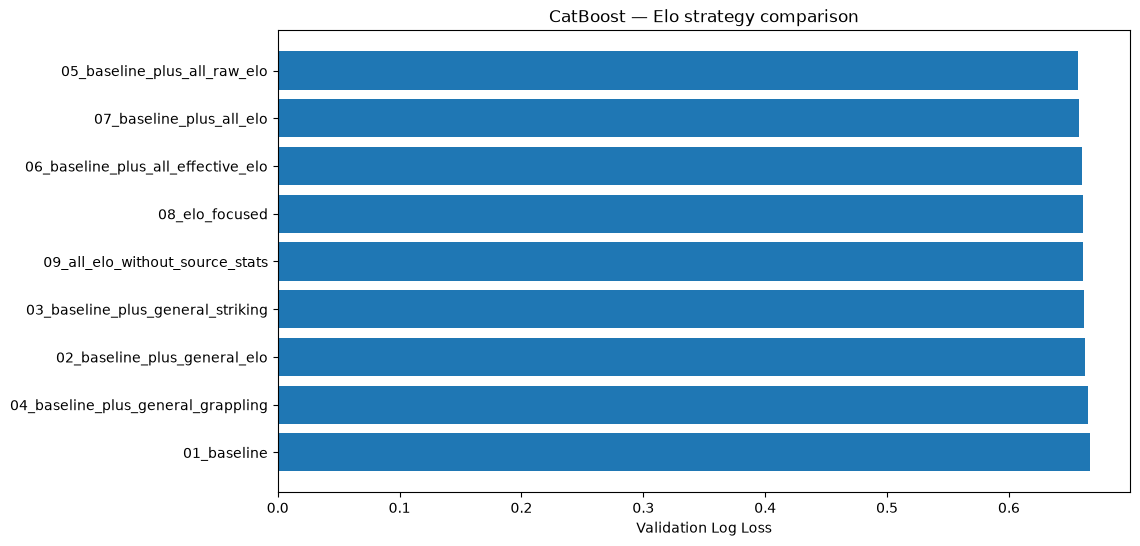

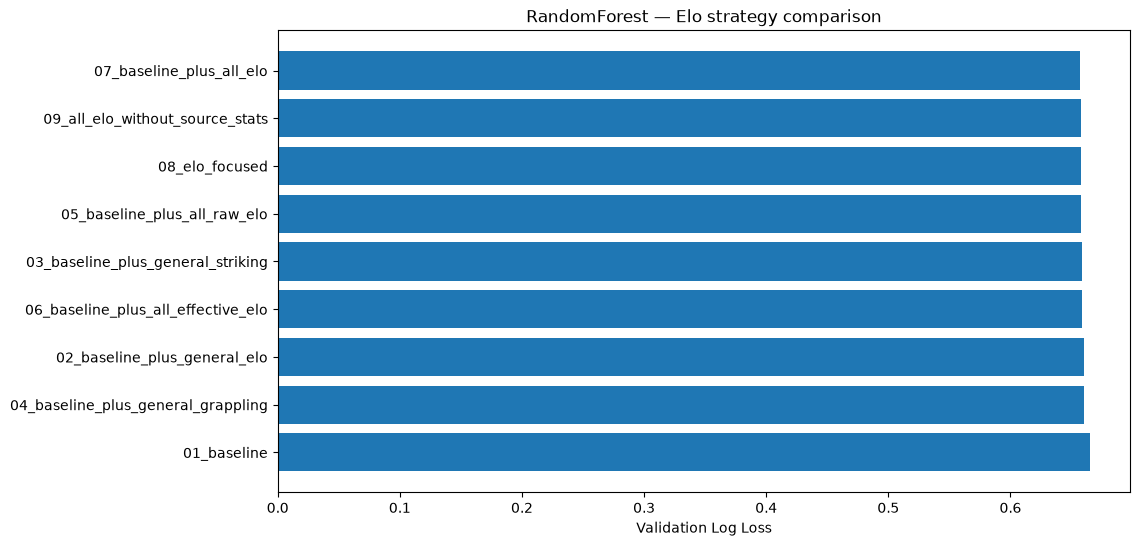

In [22]:
for model_name in results_df["model"].unique():
    plot_df = (
        results_df[results_df["model"] == model_name]
        .sort_values("log_loss", ascending=True)
    )

    plt.figure(figsize=(11, 6))
    plt.barh(plot_df["strategy"], plot_df["log_loss"])
    plt.gca().invert_yaxis()
    plt.xlabel("Validation Log Loss")
    plt.title(f"{model_name} — Elo strategy comparison")
    plt.show()


## Raw Elo vs Effective Elo

This comparison directly tests the inactivity decay.

If `all_effective_elo` consistently beats `all_raw_elo`, the decay is adding predictive value.

If raw Elo is better, the current decay may be too aggressive or may not be modelling inactivity correctly.

If the strategy using **both** wins, the model may benefit from seeing historical ability and current adjusted ability separately.

In [23]:
decay_strategy_names = [
    "05_baseline_plus_all_raw_elo",
    "06_baseline_plus_all_effective_elo",
    "07_baseline_plus_all_elo",
]

decay_comparison = (
    results_df[
        (results_df["model"] == "CatBoost")
        & (results_df["strategy"].isin(decay_strategy_names))
    ]
    .sort_values("log_loss")
)

display(decay_comparison[
    ["strategy", "n_features", "log_loss", "brier", "roc_auc", "accuracy", "ece_10"]
])


,strategy,n_features,log_loss,brier,roc_auc,accuracy,ece_10
0,05_baseline_plus_all_raw_elo,145,0.656673,0.232383,0.652561,0.609160,0.025630
1,07_baseline_plus_all_elo,160,0.657812,0.232735,0.652489,0.615267,0.023814
2,06_baseline_plus_all_effective_elo,148,0.659669,0.233693,0.646563,0.612977,0.023375


## Specialized Elo contribution

Here I compare:

- General Elo only
- General + Striking
- General + Grappling
- All Elo

This tells me whether the specialized ratings contain useful information beyond overall fight strength.

In [24]:
specialized_strategy_names = [
    "02_baseline_plus_general_elo",
    "03_baseline_plus_general_striking",
    "04_baseline_plus_general_grappling",
    "07_baseline_plus_all_elo",
]

specialized_comparison = (
    results_df[
        (results_df["model"] == "CatBoost")
        & (results_df["strategy"].isin(specialized_strategy_names))
    ]
    .sort_values("log_loss")
)

display(specialized_comparison[
    ["strategy", "n_features", "log_loss", "brier", "roc_auc", "accuracy", "ece_10"]
])


,strategy,n_features,log_loss,brier,roc_auc,accuracy,ece_10
1,07_baseline_plus_all_elo,160,0.657812,0.232735,0.652489,0.615267,0.023814
5,03_baseline_plus_general_striking,142,0.661619,0.234744,0.640230,0.611450,0.025738
6,02_baseline_plus_general_elo,133,0.662733,0.235221,0.638089,0.600000,0.029568
7,04_baseline_plus_general_grappling,151,0.665209,0.236374,0.633635,0.601527,0.018570


## Do I still need the original statistics?

This is one of the most important ablations.

The specialized Elo ratings are built partly from significant strikes, knockdowns, takedowns, control, submissions and reversals.

However, Elo and the raw historical statistics represent different information:

- the statistics describe **how a fighter performs**,
- Elo attempts to describe **how strong that performance is relative to the level of the opposition**.

I compare the full model against the model where those source statistics are removed.

In [25]:
source_stat_strategy_names = [
    "01_baseline",
    "07_baseline_plus_all_elo",
    "08_elo_focused",
    "09_all_elo_without_source_stats",
]

source_stat_comparison = (
    results_df[
        (results_df["model"] == "CatBoost")
        & (results_df["strategy"].isin(source_stat_strategy_names))
    ]
    .sort_values("log_loss")
)

display(source_stat_comparison[
    ["strategy", "n_features", "log_loss", "brier", "roc_auc", "accuracy", "ece_10"]
])


,strategy,n_features,log_loss,brier,roc_auc,accuracy,ece_10
1,07_baseline_plus_all_elo,160,0.657812,0.232735,0.652489,0.615267,0.023814
3,08_elo_focused,64,0.660876,0.234349,0.642739,0.612977,0.021496
4,09_all_elo_without_source_stats,97,0.661162,0.234478,0.642083,0.604580,0.019206
8,01_baseline,116,0.666209,0.236907,0.629929,0.592366,0.031311


## Reliability curves

Since I care about probability quality, I also compare calibration.

A strategy may improve accuracy while making its probabilities worse. That would not necessarily be an improvement for this project.

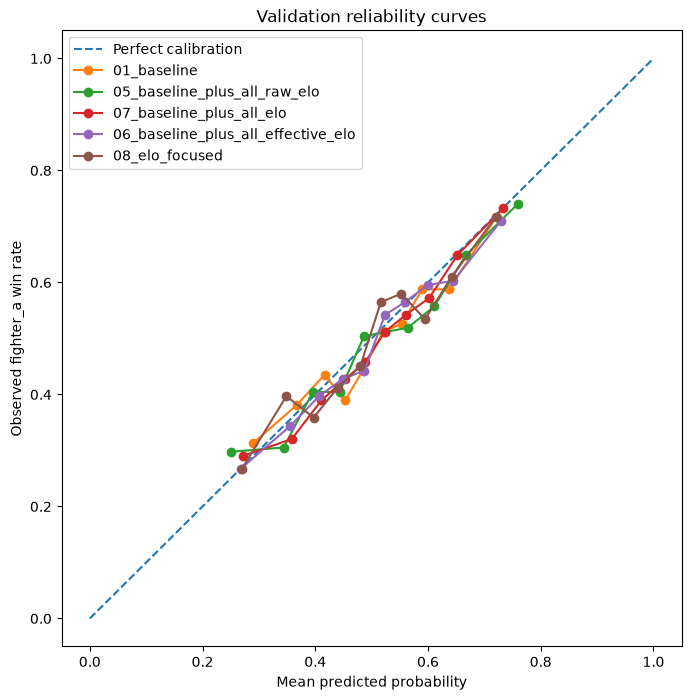

In [26]:
catboost_results = results_df[results_df["model"] == "CatBoost"].copy()
top_catboost_strategies = (
    catboost_results
    .sort_values("log_loss")
    .head(4)["strategy"]
    .tolist()
)

# I always include the baseline for reference.
strategies_to_plot = list(dict.fromkeys(
    ["01_baseline"] + top_catboost_strategies
))

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

y_validation = validation_df["target"].astype(int)

for strategy_name in strategies_to_plot:
    probs = validation_predictions[("CatBoost", strategy_name)]

    fraction_positive, mean_predicted = calibration_curve(
        y_validation,
        probs,
        n_bins=10,
        strategy="quantile",
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=strategy_name,
    )

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fighter_a win rate")
plt.title("Validation reliability curves")
plt.legend()
plt.show()


## Inspect the best CatBoost strategy

I select the best feature strategy using **validation Log Loss only**.

I then inspect CatBoost feature importance to understand whether Elo is actually being used, rather than only being present in the dataset.

In [27]:
catboost_validation = (
    results_df[results_df["model"] == "CatBoost"]
    .sort_values("log_loss")
    .reset_index(drop=True)
)

best_strategy_name = catboost_validation.iloc[0]["strategy"]
best_validation_logloss = catboost_validation.iloc[0]["log_loss"]

print("Best validation strategy:", best_strategy_name)
print(f"Validation Log Loss: {best_validation_logloss:.6f}")

best_features = strategies[best_strategy_name]
best_model = trained_models[("CatBoost", best_strategy_name)]

feature_importance = pd.DataFrame({
    "feature": best_features,
    "importance": best_model.get_feature_importance(),
}).sort_values("importance", ascending=False)

feature_importance["is_elo"] = (
    feature_importance["feature"].str.contains("elo_")
    | feature_importance["feature"].str.endswith("_is_debutant")
)

display(feature_importance.head(40))

print(
    "Total importance assigned to Elo-related features:",
    feature_importance.loc[feature_importance["is_elo"], "importance"].sum(),
)


Best validation strategy: 05_baseline_plus_all_raw_elo
Validation Log Loss: 0.656673


,feature,importance,is_elo
69,fighter_a_reach_cm,10.708176,False
72,fighter_b_reach_cm,9.099319,False
110,diff_age_years,4.020861,False
125,diff_elo_striking_raw_before,3.326931,True
70,fighter_a_age_years,2.820649,False
109,diff_reach_cm,1.864328,False
127,diff_elo_grappling_defense_raw_before,1.762153,True
56,fighter_b_sig_str_defense_before,1.721042,False
94,diff_sig_str_absorbed_per_min_before,1.586193,False
22,fighter_a_sig_str_defense_before,1.563755,False


Total importance assigned to Elo-related features: 19.647980278977577


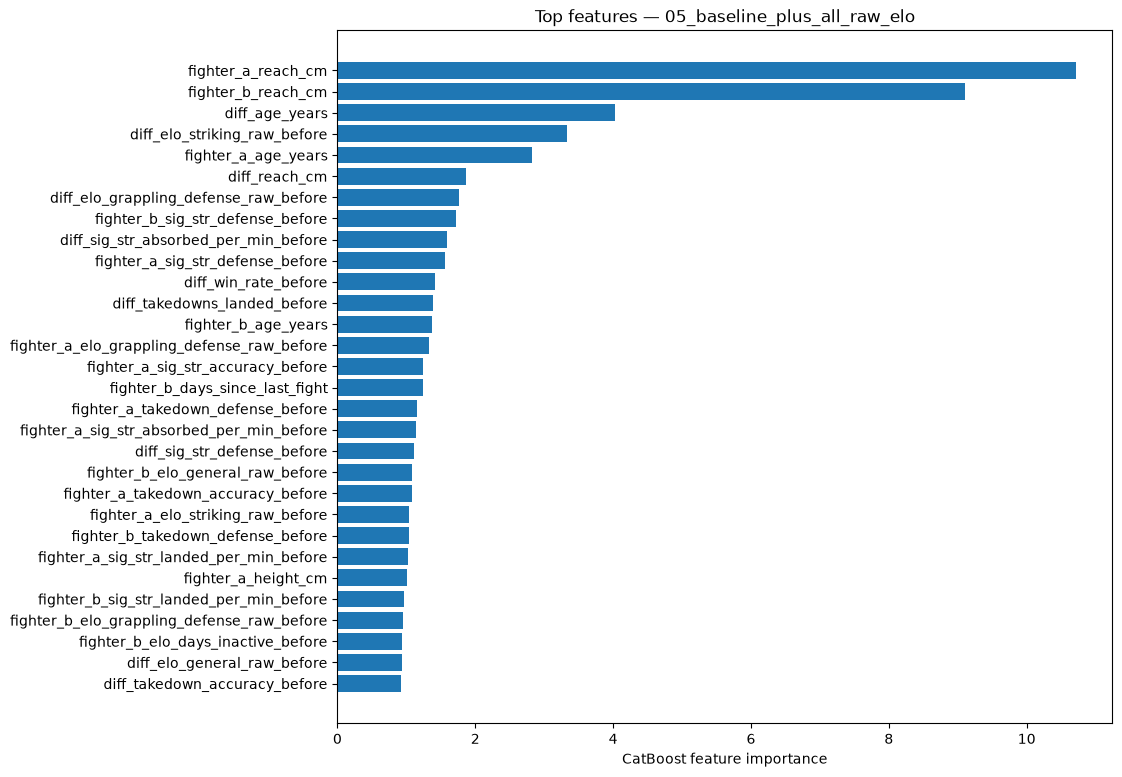

In [28]:
top_importance = feature_importance.head(30).sort_values("importance")

plt.figure(figsize=(10, 9))
plt.barh(top_importance["feature"], top_importance["importance"])
plt.xlabel("CatBoost feature importance")
plt.title(f"Top features — {best_strategy_name}")
plt.show()


## Elo-specific feature importance

The global importance plot can hide Elo variables behind other strong features, so I also inspect the Elo block separately.

,feature,importance,is_elo
125,diff_elo_striking_raw_before,3.326931,True
127,diff_elo_grappling_defense_raw_before,1.762153,True
119,fighter_a_elo_grappling_defense_raw_before,1.334841,True
120,fighter_b_elo_general_raw_before,1.087405,True
117,fighter_a_elo_striking_raw_before,1.041937,True
123,fighter_b_elo_grappling_defense_raw_before,0.956672,True
139,fighter_b_elo_days_inactive_before,0.932674,True
124,diff_elo_general_raw_before,0.930926,True
116,fighter_a_elo_general_raw_before,0.902534,True
121,fighter_b_elo_striking_raw_before,0.852460,True


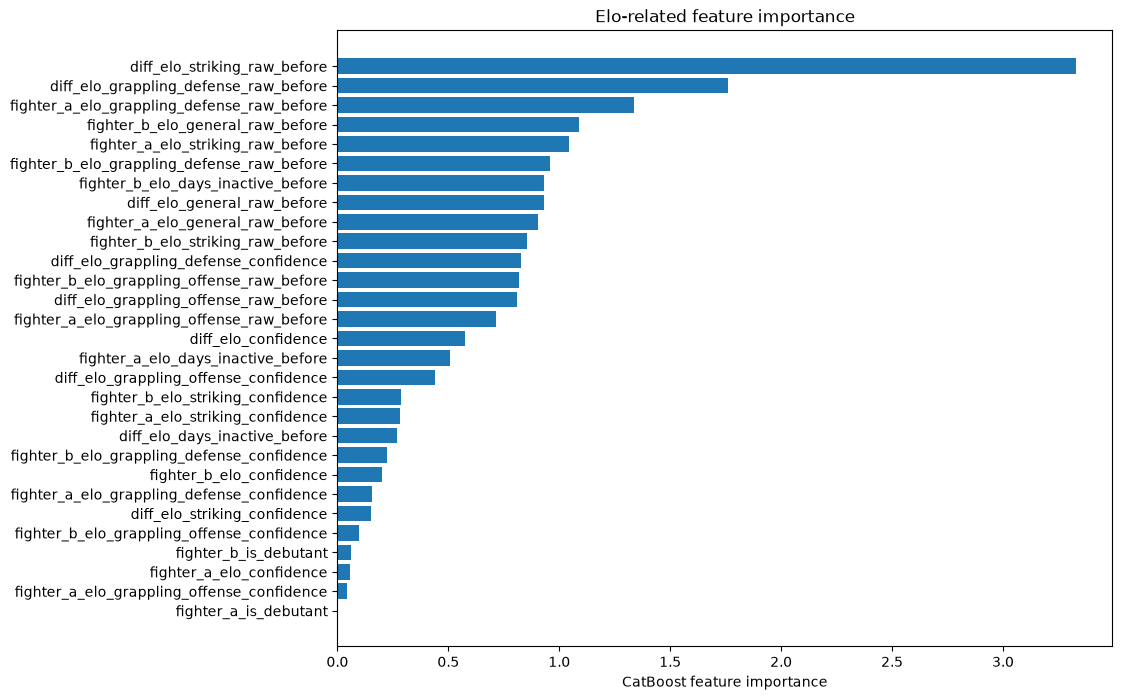

In [29]:
elo_importance = feature_importance[feature_importance["is_elo"]].copy()

if elo_importance.empty:
    print("The best strategy does not contain Elo features.")
else:
    display(elo_importance.head(40))

    plot_elo_importance = elo_importance.head(30).sort_values("importance")

    plt.figure(figsize=(10, 8))
    plt.barh(plot_elo_importance["feature"], plot_elo_importance["importance"])
    plt.xlabel("CatBoost feature importance")
    plt.title("Elo-related feature importance")
    plt.show()


## Optional final test

I keep this disabled while I am still changing the Elo system.

Once I have decided that the Elo formulas, feature strategy and model configuration are final, I can set:

```python
RUN_FINAL_TEST = True
```

Then I train the selected strategy on **train + validation** and evaluate it once on the untouched test period.

This avoids choosing Elo formulas based on repeated test-set feedback.

In [30]:
if RUN_FINAL_TEST:
    final_train_df = pd.concat(
        [train_df, validation_df],
        ignore_index=True,
    )

    final_features = strategies[best_strategy_name]
    final_cat_features = [
        col for col in final_features
        if col in categorical_features
    ]

    X_final_train = prepare_catboost_frame(
        final_train_df,
        final_features,
        final_cat_features,
    )
    X_test = prepare_catboost_frame(
        test_df,
        final_features,
        final_cat_features,
    )

    y_final_train = final_train_df["target"].astype(int)
    y_test = test_df["target"].astype(int)

    # I use the best iteration found during validation as the final training length.
    best_iteration = int(
        catboost_validation.loc[
            catboost_validation["strategy"] == best_strategy_name,
            "best_iteration",
        ].iloc[0]
    )

    final_params = CATBOOST_PARAMS.copy()
    final_params["iterations"] = max(best_iteration + 1, 1)

    final_model = CatBoostClassifier(**final_params)

    final_model.fit(
        X_final_train,
        y_final_train,
        cat_features=final_cat_features,
        verbose=False,
    )

    test_probabilities = final_model.predict_proba(X_test)[:, 1]
    test_metrics = evaluate_probabilities(y_test, test_probabilities)

    final_test_results = pd.DataFrame([{
        "strategy": best_strategy_name,
        "train_rows": len(final_train_df),
        "test_rows": len(test_df),
        **test_metrics,
    }])

    display(final_test_results)

    final_test_path = RESULTS_DIR / "final_elo_test_results.csv"
    final_test_results.to_csv(final_test_path, index=False)

    print("Saved:", final_test_path)
else:
    print(
        "Final test evaluation is disabled. "
        "Set RUN_FINAL_TEST = True only after the Elo strategy is finalized."
    )


Final test evaluation is disabled. Set RUN_FINAL_TEST = True only after the Elo strategy is finalized.


## Experiment notes

We have seen that the addition of Elo is fruitful.


And that it doesn´t substitute the raw stats, but complement them. I would say that:
- Raw stats tell us how someone fights
- Elo tells us the level of his previous opponents and how he performed

We have also seen that regular, grappling defense and Striking Elos are very helpful, however grappling offense and decay over time are not performing as expected.

Now that we have verified that ELO IS HELPFUL, we will devote our next Notebook to the tweak and optimise its formulas.